**SAPIANS** · SCC5819 · MÓDULO 06 — PFI · MOLNAR, CAP. 23

# O embaralhamento muda a coluna certa — e só ela?

Depois dos métodos locais, a PFI pergunta pela dependência preditiva global do mesmo modelo. O walkthrough mostra o experimento; este caderno confronta o núcleo com um oráculo independente e com a biblioteca.

[README do módulo](../README.md) · [outline da aula](../lecture/outline.md) · [walkthrough](pfi_walkthrough.ipynb) · [Colab](https://colab.research.google.com/github/wbendinelli/interpretable-ml-lectures/blob/main/modules/06-pfi/notebooks/pfi_internals.ipynb)

---

**Objetivos.** Conferir transporte posicional, preservação de categorias e de alvos, ausência de retreino, sinais e dispersão da importância; distinguir uma validação sintética dos registros reais do curso.


In [1]:
%pip install -q numpy pandas pyarrow scikit-learn xgboost matplotlib


Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib
import itertools
import json
import os
import subprocess
from pathlib import Path
import sys
import tempfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from xgboost import XGBClassifier

REPO = Path(os.environ.get("INTERPRETABLE_ML_REPO", Path.cwd())).resolve()
while REPO != REPO.parent and not (REPO / "tools/srag_70_explain.py").exists():
    REPO = REPO.parent
if not (REPO / "tools/srag_70_explain.py").exists():
    REPO = Path(tempfile.gettempdir()) / "interpretable-ml-lectures"
    if not REPO.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/wbendinelli/interpretable-ml-lectures.git",
                        str(REPO)], check=True, capture_output=True)
sys.path.insert(0, str(REPO / "tools"))
import sapians as SP
import srag_70_explain as E
import srag_62_pfi as P
import srag_pfi_walkthrough as W
import srag_60_model as M
import srag_73_teaching_demo as H

WORK = Path(os.environ.get("PFI_WORK_DIR", tempfile.mkdtemp(prefix="pfi-internals-")))
WORK.mkdir(parents=True, exist_ok=True)
assert not WORK.is_relative_to(REPO)
os.chdir(WORK)
SP.aplicar()
RANDOM_STATE = 42
print("Semente dos exemplos sintéticos:", SP.pt_int(RANDOM_STATE))
print("Os testes sintéticos abaixo não medem desempenho do modelo SRAG.")


Semente dos exemplos sintéticos: 42
Os testes sintéticos abaixo não medem desempenho do modelo SRAG.


## §1 — O contrato que a aula executa

O núcleo recebe um preditor já ajustado. `permutar_colunas` copia a matriz original e seleciona os doadores por posição, preservando o índice de destino. Uma tupla de colunas usa a mesma linha doadora em todas elas. `trace_pfi` converte as probabilidades da classe positiva para precisão dupla e recebe a função de perda do chamador.

A ordem precisa ser uma bijeção das posições. A identidade é permitida: uma permutação aleatória não precisa mover todas as linhas. Para os subgrupos, a ordem é construída de modo que doador e destino pertençam ao mesmo grupo; isso condiciona apenas no agrupamento escolhido.


In [3]:
x = pd.DataFrame(
    {"signal": [0., 1., 2., 3., 4., 5.], "noise": [0., 1., 0., 1., 0., 1.]},
    index=[90, 3, 12, 5, 21, 7],
)
y = np.array([0, 0, 0, 1, 1, 1])
model = LogisticRegression(C=2, random_state=RANDOM_STATE).fit(x, y)
assert np.array_equal(model.classes_, [0, 1])
x_snapshot = x.copy(deep=True)
y_snapshot = y.copy()
identity = np.arange(len(x))
before, identity_after = E.trace_pfi(model, x, y, "signal", [identity], log_loss)
np.testing.assert_allclose(identity_after, before, rtol=0, atol=0)
pd.testing.assert_frame_equal(x, x_snapshot)
np.testing.assert_array_equal(y, y_snapshot)
print("Linhas sintéticas:", SP.pt_int(len(x)), "; índice propositalmente não sequencial.")
print("log loss original sintético:", SP.pt(before, 8))
print("Mudança com ordem identidade:", SP.pt(identity_after[0] - before, 8))
print("Classe positiva na segunda coluna; alvos e matriz original preservados.")


Linhas sintéticas: 6 ; índice propositalmente não sequencial.
log loss original sintético: 0,15968774
Mudança com ordem identidade: 0,00000000
Classe positiva na segunda coluna; alvos e matriz original preservados.


**O que olhar.** A identidade produz mudança nula. O índice deliberadamente fora de ordem detectaria o erro clássico de atribuir uma série embaralhada que pandas realinha pelos rótulos.

## §2 — Um oráculo independente: enumerar as ordens possíveis

Para uma matriz sintética pequena, podemos percorrer todas as permutações. O oráculo move diretamente uma coluna de um array NumPy, sem chamar o núcleo ou usar a atribuição de séries de pandas. Depois calcula a média dos perdas logarítmicas explicitamente. Comparamos cada perda, não apenas uma média que poderia ocultar erros de alinhamento.


In [4]:
all_orders = [np.asarray(order) for order in itertools.permutations(range(len(x)))]
exact_before, exact_after = E.trace_pfi(model, x, y, "signal", all_orders, log_loss)
raw = x.to_numpy()
oracle_errors = []
for order in all_orders:
    changed_array = raw.copy()
    changed_array[:, 0] = raw[order, 0]
    changed_frame = pd.DataFrame(changed_array, columns=x.columns)
    probability = model.predict_proba(changed_frame)[:, 1]
    oracle_errors.append(float(np.mean(np.where(y == 1, -np.log(probability), -np.log1p(-probability)))))
oracle_errors = np.asarray(oracle_errors)
np.testing.assert_allclose(exact_after, oracle_errors, rtol=0, atol=1e-15)
np.testing.assert_allclose(exact_before, before, rtol=0, atol=0)
wrapper_before, wrapper_after = W.trace_feature(model, x, y, "signal", all_orders, log_loss)
np.testing.assert_allclose(wrapper_after, exact_after, rtol=0, atol=0)
assert wrapper_before == exact_before
exact_delta = exact_after - exact_before
print("Ordens enumeradas:", SP.pt_int(len(all_orders)))
print("Maior discrepância núcleo versus oráculo:", SP.pt(np.max(np.abs(exact_after - oracle_errors)), 15))
print("Wrapper didático e núcleo: mesmos resultados em todas as ordens.")
print("PFI média da distribuição sintética exata:", SP.pt(exact_delta.mean(), 8))
print("SD da distribuição exata, ddof =", SP.pt_int(0), ":", SP.pt(exact_delta.std(ddof=0), 8))


Ordens enumeradas: 720
Maior discrepância núcleo versus oráculo: 0,000000000000000
Wrapper didático e núcleo: mesmos resultados em todas as ordens.
PFI média da distribuição sintética exata: 1,08941557
SD da distribuição exata, ddof = 0 : 0,55322058


**O que olhar.** O teste cobre cada ordem possível dessa matriz. A SD da enumeração usa a distribuição completa das ordens, por isso a convenção é populacional. Este é um teste de implementação sintético, não uma estimativa da PFI de SRAG.

## §3 — Confronto com scikit-learn

A biblioteca trabalha com pontuações nas quais valores maiores são melhores. Fornecemos o negativo do log loss; assim, a queda de pontuação coincide com o aumento de perda do núcleo.

A mesma semente não torna iguais os sorteios de `RandomState`, usado pela biblioteca, e de `default_rng`, usado no protocolo da aula. O confronto independente usa a distribuição exata como referência. A comparação de médias é tolerada pela dispersão de Monte Carlo dos sorteios, sem exigir coincidência linha a linha.

A SD que scikit-learn retorna usa a convenção populacional. Conferimos também a conversão para a SD amostral utilizada na aula.


Sorteios independentes de scikit-learn: 6.000
PFI média sintética exata: 1,08941557
PFI média de scikit-learn: 1,08428100
Diferença absoluta entre médias: 0,00513456
Erro Monte Carlo da média da biblioteca: 0,00712734
Critério de conferência: 4 vezes esse erro; critério atendido.
SD de scikit-learn, ddof = 0 : 0,55203531
SD amostral após conversão, ddof = 1 : 0,55208132
Conversão de SD confere com os sorteios individuais.
figura: figures_generated/pfi-internals-library.png


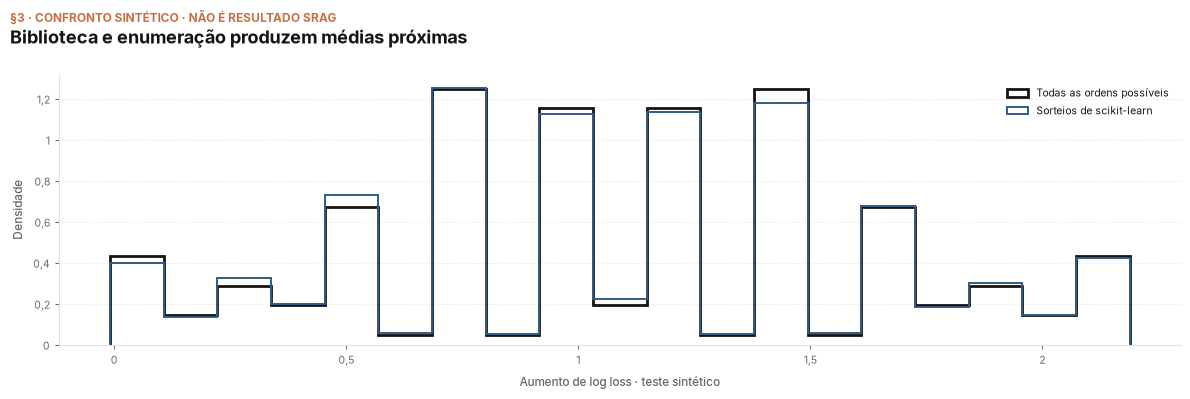

In [5]:
library_repeats = 6000
library = permutation_importance(
    model, x, y,
    scoring=lambda fitted, inputs, target: -log_loss(
        target, fitted.predict_proba(inputs)[:, 1]
    ),
    n_repeats=library_repeats,
    random_state=RANDOM_STATE,
)
library_delta = library.importances[0]
library_mcse = library_delta.std(ddof=1) / np.sqrt(library_repeats)
mean_gap = abs(library_delta.mean() - exact_delta.mean())
assert mean_gap < 4 * library_mcse
np.testing.assert_allclose(library.importances_mean[0], library_delta.mean(), rtol=0, atol=0)
np.testing.assert_allclose(library.importances_std[0], library_delta.std(ddof=0), rtol=0, atol=0)
converted_sd = library.importances_std[0] * np.sqrt(library_repeats / (library_repeats - 1))
np.testing.assert_allclose(converted_sd, library_delta.std(ddof=1), rtol=0, atol=1e-15)
print("Sorteios independentes de scikit-learn:", SP.pt_int(library_repeats))
print("PFI média sintética exata:", SP.pt(exact_delta.mean(), 8))
print("PFI média de scikit-learn:", SP.pt(library_delta.mean(), 8))
print("Diferença absoluta entre médias:", SP.pt(mean_gap, 8))
print("Erro Monte Carlo da média da biblioteca:", SP.pt(library_mcse, 8))
print("Critério de conferência:", SP.pt_int(4), "vezes esse erro; critério atendido.")
print("SD de scikit-learn, ddof =", SP.pt_int(0), ":", SP.pt(library.importances_std[0], 8))
print("SD amostral após conversão, ddof =", SP.pt_int(1), ":", SP.pt(converted_sd, 8))
print("Conversão de SD confere com os sorteios individuais.")

fig, ax = plt.subplots(figsize=SP.FAIXA)
bins = np.linspace(min(exact_delta.min(), library_delta.min()), max(exact_delta.max(), library_delta.max()), 20)
ax.hist(exact_delta, bins=bins, density=True, histtype="step", linewidth=2, color=SP.ESCURO, label="Todas as ordens possíveis")
ax.hist(library_delta, bins=bins, density=True, histtype="step", linewidth=1.4, color=SP.AZUL, label="Sorteios de scikit-learn")
ax.set_xlabel("Aumento de log loss · teste sintético")
ax.set_ylabel("Densidade")
ax.legend(frameon=False)
SP.titulo(fig, "Biblioteca e enumeração produzem médias próximas", "§3 · CONFRONTO SINTÉTICO · NÃO É RESULTADO SRAG")
SP.salvar(fig, "pfi-internals-library")
display(fig)
plt.close(fig)


**O que olhar.** As médias concordam dentro do critério de Monte Carlo declarado. A conversão de SD é exata; não seria correto comparar a SD amostral da aula diretamente com o campo `importances_std` da biblioteca.

## §4 — Invariantes que uma média correta não garante

Uma segunda matriz sintética mistura categorias nativas, campos booleanos e números. Conferimos índice, tipos, níveis e as colunas que ficam fixas. O embaralhamento conjunto deve preservar as tuplas observadas; o restrito a subgrupos deve conservar o agrupamento de cada registro.

Um preditor de auditoria rejeita chamadas de treinamento. Suas probabilidades saem em precisão simples; a perda registra o tipo que recebe para conferir a conversão do núcleo. Esse preditor foi construído apenas para o teste.


In [6]:
categories = ["desconhecido", "nao", "sim"]
cx = pd.DataFrame({
    "heart": pd.Categorical(["sim", "nao", "desconhecido", "nao", "sim", "desconhecido"], categories=categories),
    "diabetes": pd.Categorical(["sim", "nao", "sim", "desconhecido", "nao", "desconhecido"], categories=categories),
    "fixed_bool": [True, False, True, False, True, False],
    "fixed_number": np.arange(6, dtype=np.int32),
}, index=[91, 2, 18, 4, 52, 9])
cy = np.array([1, 0, 0, 1, 0, 1])
cx_snapshot = cx.copy(deep=True)
cy_snapshot = cy.copy()
order = np.array([2, 4, 0, 5, 1, 3])

single = E.permutar_colunas(cx, "heart", order)
np.testing.assert_array_equal(single["heart"].to_numpy(), cx["heart"].to_numpy()[order])
pd.testing.assert_frame_equal(single.drop(columns="heart"), cx.drop(columns="heart"))
assert single.index.equals(cx.index)
assert single.dtypes.equals(cx.dtypes)
assert single["heart"].cat.categories.equals(cx["heart"].cat.categories)

joint_order = np.array([5, 0, 4, 1, 3, 2])
joint = E.permutar_colunas(cx, ("heart", "diabetes"), joint_order)
for column in ["heart", "diabetes"]:
    np.testing.assert_array_equal(joint[column].to_numpy(), cx[column].to_numpy()[joint_order])
assert not joint["diabetes"].equals(cx["diabetes"])
original_pairs = cx.groupby(["heart", "diabetes"], observed=False).size()
joint_pairs = joint.groupby(["heart", "diabetes"], observed=False).size()
pd.testing.assert_series_equal(joint_pairs, original_pairs)
pd.testing.assert_frame_equal(joint.drop(columns=["heart", "diabetes"]), cx.drop(columns=["heart", "diabetes"]))
# This explicit donor order stays in each original diabetes group.
np.testing.assert_array_equal(cx["diabetes"].to_numpy()[order], cx["diabetes"].to_numpy())
within = E.permutar_colunas(cx, "heart", order)
pd.testing.assert_series_equal(within.groupby(["heart", "diabetes"], observed=False).size(), original_pairs)
pd.testing.assert_series_equal(within["diabetes"], cx["diabetes"])

class AuditPredictor:
    def __init__(self):
        self.fit_calls = 0
        self.prediction_calls = 0
    def fit(self, *args, **kwargs):
        self.fit_calls += 1
        raise AssertionError("PFI não deve chamar fit.")
    def predict_proba(self, inputs):
        self.prediction_calls += 1
        probability = inputs["heart"].map({"nao": .1, "sim": .8, "desconhecido": .4}).astype(float).to_numpy(dtype=np.float32)
        return np.column_stack([1 - probability, probability])

probability_types = []
def audit_loss(target, probability):
    probability_types.append(probability.dtype)
    return float(log_loss(target, probability))

audit_model = AuditPredictor()
cat_before, cat_after = E.trace_pfi(audit_model, cx, cy, "heart", [order, np.arange(len(cx))], audit_loss)
assert cat_after[-1] == cat_before
assert audit_model.fit_calls == 0
assert all(dtype == np.dtype("float64") for dtype in probability_types)
pd.testing.assert_frame_equal(cx, cx_snapshot)
np.testing.assert_array_equal(cy, cy_snapshot)
ignored_before, ignored_after = E.trace_pfi(audit_model, cx, cy, "fixed_number", [order, np.arange(len(cx))], audit_loss)
np.testing.assert_allclose(ignored_after, ignored_before, rtol=0, atol=0)
print("Tipos, níveis de categoria, índice e campos fixos: preservados.")
print("Tuplas preservadas no embaralhamento conjunto: verdadeiro.")
print("Subgrupos de diabetes preservados pela ordem restrita: verdadeiro.")
print("Mudança após restaurar a identidade:", SP.pt(cat_after[-1] - cat_before, 8))
print("Mudança da variável ignorada pelo preditor:", SP.pt(np.max(np.abs(ignored_after - ignored_before)), 8))
print("Chamadas de treinamento:", SP.pt_int(audit_model.fit_calls))
print("Todas as perdas receberam probabilidade float64:", all(dtype == np.dtype("float64") for dtype in probability_types))

invalid_cases = [
    ("heart", np.array([0, 0, 2, 3, 4, 5])),
    ("heart", np.array([0, 1, 2, 3, 4])),
    ("heart", np.array([0, 1, 2, 3, 4, 6])),
    ("heart", np.arange(len(cx), dtype=float)),
    ("missing", np.arange(len(cx))),
    (("heart", "heart"), np.arange(len(cx))),
    ((), np.arange(len(cx))),
]
rejected = 0
for columns, bad_order in invalid_cases:
    try:
        E.permutar_colunas(cx, columns, bad_order)
    except ValueError:
        rejected += 1
assert rejected == len(invalid_cases)
invalid_studies = [{"repeats": 0}, {"repeats": 1}, {"repeats": 2.5}, {"split": "train"}]
for kwargs in invalid_studies:
    try:
        P.study(WORK / "invalid-study", **kwargs)
    except ValueError:
        continue
    raise AssertionError("Contrato inválido deveria ser rejeitado antes do ajuste.")
print("Pedidos inválidos rejeitados pelo transporte:", SP.pt_int(rejected))
print("Pedidos inválidos rejeitados pelo estudo:", SP.pt_int(len(invalid_studies)))


Tipos, níveis de categoria, índice e campos fixos: preservados.
Tuplas preservadas no embaralhamento conjunto: verdadeiro.
Subgrupos de diabetes preservados pela ordem restrita: verdadeiro.
Mudança após restaurar a identidade: 0,00000000
Mudança da variável ignorada pelo preditor: 0,00000000
Chamadas de treinamento: 0
Todas as perdas receberam probabilidade float64: True
Pedidos inválidos rejeitados pelo transporte: 7
Pedidos inválidos rejeitados pelo estudo: 4


**O que olhar.** A variável ignorada não muda as probabilidades. Restaurar a identidade após um sorteio confirma que a perturbação não se acumula. O teste conjunto conserva os pares, enquanto o teste restrito conserva o grupo de cada destino; nenhum deles protege todas as relações com outras entradas.

## §5 — Conferir os registros reais que alimentam os slides

Agora lemos os resultados comprometidos de SRAG. Esta seção verifica integridade da amostra, ordens reproduzidas, sinais, médias, SD, erro Monte Carlo, ranks e equivalência entre diferença e razão. Não reexecuta o ajuste nem a busca de modelos. O walkthrough reconstrói o preditor e confere o traço real de idade.

A avaliação usa o modelo e o teste histórico fixos. A dispersão desses sorteios mede somente variação da permutação. O teste temporal já observado é exploratório.


In [7]:
gold_dir = REPO / "modules/00-dataset/gold"
record = json.loads((gold_dir / "pfi_ranking.json").read_text())
slides = json.loads((gold_dir / "pfi_slide_explainer.json").read_text())
protocol = record["protocol"]
assert protocol["repeats"] >= 2
assert protocol["split"] == "test"
sample_hash = hashlib.sha256((gold_dir / "gold_covid_obito_sample.parquet").read_bytes()).hexdigest()
assert sample_hash == protocol["sample_sha256"]
rng = np.random.default_rng(protocol["permutation_seed"])
record_orders = [rng.permutation(protocol["n_evaluation"]) for _ in range(protocol["repeats"])]
orders_hash = hashlib.sha256(np.asarray(record_orders).tobytes()).hexdigest()
assert orders_hash == protocol["permutation_orders_sha256"]
mean_discrepancies, sd_discrepancies = [], []
for row in record["rows"]:
    for metric, result in row["metrics"].items():
        after = np.asarray(result["after"])
        delta = np.asarray(result["delta"])
        direction = -1 if metric == "auc" else 1
        assert len(after) == protocol["repeats"]
        np.testing.assert_allclose(delta, direction * (after - record["original"][metric]), rtol=0, atol=1e-15)
        mean_discrepancies.append(abs(delta.mean() - result["mean"]))
        sd_discrepancies.append(abs(delta.std(ddof=1) - result["sd"]))
        np.testing.assert_allclose(result["after_mean"], after.mean(), rtol=0, atol=1e-15)
        np.testing.assert_allclose(result["after_sd"], after.std(ddof=1), rtol=0, atol=1e-15)
        np.testing.assert_allclose(result["mcse"], delta.std(ddof=1) / np.sqrt(len(delta)), rtol=0, atol=1e-15)
for metric in record["original"]:
    deltas = np.asarray([row["metrics"][metric]["delta"] for row in record["rows"]])
    ranks = pd.DataFrame(deltas).rank(ascending=False, method="average").to_numpy()
    rank_order = np.argsort(-deltas.mean(axis=1), kind="stable")
    for position, row_index in enumerate(rank_order):
        result = record["rows"][row_index]["metrics"][metric]
        assert result["rank"] == position + 1
        np.testing.assert_allclose(result["rank_repeats"], ranks[row_index], rtol=0, atol=0)
        np.testing.assert_allclose(result["rank_mean"], ranks[row_index].mean(), rtol=0, atol=1e-15)
        np.testing.assert_allclose(result["rank_sd"], ranks[row_index].std(ddof=1), rtol=0, atol=1e-15)
        assert result["top10_fraction"] == np.mean(ranks[row_index] <= 10)

import srag_72_pfi_presentation as Q
public = Q.project_aggregates(slides)
baseline = record["original"]["logloss"]
assert baseline > 0
for row in public["rows"]:
    canonical = next(r for r in record["rows"] if r["feature"] == row["feature"])["metrics"]["logloss"]
    assert row["before"] == baseline
    for slide_key, source_key in [("after_mean", "after_mean"), ("after_sd", "after_sd"), ("difference_mean", "mean"), ("difference_sd", "sd")]:
        np.testing.assert_allclose(row[slide_key], canonical[source_key], rtol=0, atol=1e-15)
    np.testing.assert_allclose(row["ratio_mean"], row["after_mean"] / baseline, rtol=0, atol=1e-15)
    np.testing.assert_allclose(row["ratio_sd"], row["difference_sd"] / baseline, rtol=0, atol=1e-15)
age = next(row for row in record["rows"] if row["feature"] == "idade_anos")["metrics"]["logloss"]
np.testing.assert_allclose(public["walkthrough"]["after"], age["after"], rtol=0, atol=0)
np.testing.assert_allclose(public["walkthrough"]["difference"], age["delta"], rtol=0, atol=0)
for diagnostic in public["dependence"]["results"]:
    after = np.asarray(diagnostic["after"])
    delta = np.asarray(diagnostic["difference"])
    assert len(after) == protocol["repeats"]
    np.testing.assert_allclose(delta, after - baseline, rtol=0, atol=1e-15)
    np.testing.assert_allclose(diagnostic["after_mean"], after.mean(), rtol=0, atol=1e-15)
    np.testing.assert_allclose(diagnostic["difference_mean"], delta.mean(), rtol=0, atol=1e-15)
    np.testing.assert_allclose(diagnostic["difference_sd"], delta.std(ddof=1), rtol=0, atol=1e-15)

print("SHA da amostra e SHA das ordens: conferem com o protocolo.")
print("Variáveis:", SP.pt_int(len(record["rows"])), "; métricas:", SP.pt_int(len(record["original"])), "; repetições:", SP.pt_int(protocol["repeats"]))
print("Ano do teste:", str(protocol["period"]), "; registros:", SP.pt_int(protocol["n_evaluation"]), "; óbitos:", SP.pt_int(protocol["events"]))
print("Semente registrada:", SP.pt_int(protocol["permutation_seed"]))
print("Maior discrepância de médias:", SP.pt(max(mean_discrepancies), 15))
print("Maior discrepância de SD:", SP.pt(max(sd_discrepancies), 15))
print("Resumos de gráficos conferidos:", SP.pt_int(len(public["rows"])))
print("Diagnósticos de dependência conferidos:", SP.pt_int(len(public["dependence"]["results"])))
print("Sinais e ranks conferidos para todas as métricas; traço de Age idêntico ao registro.")
print("Log loss original SRAG:", SP.pt(baseline, 8))
print("Idade, PFI média ± SD:", SP.pt(age["mean"], 8), "±", SP.pt(age["sd"], 8))


import copy
import srag_72_pfi_presentation as Q
public = Q.project_aggregates(slides)
Q.validate_aggregates(public)
assert "preview" not in public
assert set(public["dependence"]) == {"results", "protocol"}
assert Q.project_aggregates({**slides, "unselected_example": {"patient": "must not ship"}}) == public
injected = copy.deepcopy(public)
injected["study"]["patient_example"] = {"probability": 0.9}
try:
    Q.validate_aggregates(injected)
except ValueError:
    pass
else:
    raise AssertionError("An extra nested field escaped the public projection.")
misreported = copy.deepcopy(public)
misreported["rows"][0]["difference_mean"] += .01
try:
    Q.validate_aggregates(misreported)
except ValueError:
    pass
else:
    raise AssertionError("An inconsistent displayed measurement was accepted.")
print("Projeção pública: campos individuais não selecionados; injeção e número inconsistente rejeitados.")


SHA da amostra e SHA das ordens: conferem com o protocolo.
Variáveis: 40 ; métricas: 3 ; repetições: 50
Ano do teste: 2024 ; registros: 16.142 ; óbitos: 2.945
Semente registrada: 42
Maior discrepância de médias: 0,000000000000000
Maior discrepância de SD: 0,000000000000000
Resumos de gráficos conferidos: 10
Diagnósticos de dependência conferidos: 4
Sinais e ranks conferidos para todas as métricas; traço de Age idêntico ao registro.
Log loss original SRAG: 0,40901958
Idade, PFI média ± SD: 0,08463367 ± 0,00265889
Projeção pública: campos individuais não selecionados; injeção e número inconsistente rejeitados.


### A coerência da janela real do experimento global

Reconstruímos o preditor de SRAG e reproduzimos a primeira ordem global do
registro. Um transporte posicional independente preserva os tipos originais
e confere o erro de todo o teste, além das previsões das fichas receptoras
visíveis. Nenhum doador é selecionado pelo seu desfecho ou pela nova perda.
A ordem manual antiga e suas perdas ficam auditadas para registrar a correção.
A janela selecionada por desfecho não estima o desempenho global.


In [8]:
# Reproduzir o modelo e o recorte pela amostra comprometida, sem publicar índices.
case_gold = M.load_gold(gold_dir / "gold_covid_obito_sample.parquet")
case_design, _, case_design_target = M.design_matrix(case_gold)
case_train_mask = (case_gold["split"] == "train").to_numpy()
case_test_mask = (case_gold["split"] == "test").to_numpy()
srag_model = XGBClassifier(**protocol["xgb_params"]).fit(case_design.loc[case_train_mask],
                                                         case_design_target[case_train_mask])
srag_model_snapshot = bytes(srag_model.get_booster().save_raw())
case_test = case_gold.loc[case_test_mask]
historical_case = slides["preview"]
case_index = pd.concat([
    case_test[(case_test["idade_anos"] >= 18) & (case_test["y_obito"] == outcome)]
    .head(historical_case["selection"]["records_per_outcome"])
    for outcome in (0, 1)
]).sort_index().index
case_inputs = case_design.loc[case_index].reset_index(drop=True)
case_inputs_snapshot = case_inputs.copy(deep=True)
case_target = case_gold.loc[case_index, "y_obito"].to_numpy()
full_case_inputs = case_design.loc[case_test_mask].reset_index(drop=True)
full_case_target = case_design_target[case_test_mask]
case_positions = case_gold.loc[case_test_mask].index.get_indexer(case_index)
assert np.all(case_positions >= 0)
pd.testing.assert_frame_equal(full_case_inputs.iloc[case_positions].reset_index(drop=True), case_inputs)
case_payload = H.build_teaching_demo(srag_model, full_case_inputs, full_case_target,
                                     case_positions, historical_case, public["rows"], record)
case = case_payload["preview"]
case_top_fields = {"metric", "rows", "rounds", "permutation_seed", "displayed_repeat", "evaluation_n",
                   "permutation_scope", "permutation_orders_sha256", "threshold", "age_unit", "selection", "scope"}
case_row_fields = {"record", "idade_anos", "saturacao", "y_obito", "p_original",
                   "class_original", "correct_original", "loss_original",
                   "p_after_age", "class_after_age", "correct_after_age", "loss_after_age",
                   "p_after_oxygen", "class_after_oxygen", "correct_after_oxygen", "loss_after_oxygen"}
case_round_fields = {"feature", "label", "cell", "values", "shuffled_values", "probability", "predicted",
                     "correct", "individual_loss", "sample_loss_mean", "full_test_single_loss", "full_test"}
case_full_fields = {"feature", "label", "before", "after_mean", "after_sd", "difference_mean",
                    "difference_sd", "ratio_mean", "ratio_sd", "relative_increase_percent"}
assert set(case) == case_top_fields
assert set(case["selection"]) == {"records_per_outcome", "rule"}
assert [row["record"] for row in case["rows"]] == list("ABCDEFGH")
assert all(set(row) == case_row_fields for row in case["rows"])
assert all(set(round_) == case_round_fields for round_ in case["rounds"])
assert all(set(round_["full_test"]) == case_full_fields for round_ in case["rounds"])
assert case["age_unit"] == "decimal years at symptom onset"
case_target = np.asarray([row["y_obito"] for row in case["rows"]], dtype=int)
assert set(case_target) == {0, 1}
assert np.all(np.bincount(case_target) == case["selection"]["records_per_outcome"])
case_age = np.asarray([row["idade_anos"] for row in case["rows"]], dtype=np.float64)
assert np.all(case_age >= 18)
np.testing.assert_array_equal(case_age.astype(np.float32).astype(np.float64), case_age)
global_order = record_orders[0]
assert case["permutation_seed"] == protocol["permutation_seed"]
assert case["displayed_repeat"] == 1
assert case["evaluation_n"] == len(full_case_inputs)
assert case["permutation_scope"] == "full temporal test"
assert case["permutation_orders_sha256"] == orders_hash
case_original = np.asarray([row["p_original"] for row in case["rows"]], dtype=np.float64)
np.testing.assert_array_equal(case_original, [row["p_original"] for row in historical_case["rows"]])
case_threshold = float(case["threshold"])
assert 0 < case_threshold < 1
assert np.all((case_original >= 0) & (case_original <= 1))
case_original_class = (case_original >= case_threshold).astype(int)
case_original_loss = np.where(case_target == 1, -np.log(case_original), -np.log1p(-case_original))
np.testing.assert_array_equal(case_original_class, [row["class_original"] for row in case["rows"]])
np.testing.assert_array_equal(case_original_class == case_target, [row["correct_original"] for row in case["rows"]])
np.testing.assert_array_equal(case_original_loss, [row["loss_original"] for row in case["rows"]])
case_target_snapshot = case_target.copy()
case_checks = [{"estado": "Original", "Log loss do recorte": float(case_original_loss.mean()),
                "erros de classe": int(np.count_nonzero(case_original_class != case_target)),
                "valores alterados": 0, "probabilidades alteradas": 0}]
assert [(r["feature"], r["cell"]) for r in case["rounds"]] == [("idade_anos", "age"), ("saturacao", "oxygen")]
for round_ in case["rounds"]:
    feature, cell = round_["feature"], round_["cell"]
    original_values = case_inputs[feature].to_numpy()
    np.testing.assert_array_equal(original_values, round_["values"])
    # Oráculo: transporta o array do TESTE INTEIRO, sem chamar permutar_colunas.
    full_moved_values = full_case_inputs[feature].to_numpy()[global_order]
    moved_values = full_moved_values[case_positions]
    np.testing.assert_array_equal(moved_values, round_["shuffled_values"])
    independent_inputs = full_case_inputs.copy(deep=True)
    if isinstance(full_case_inputs[feature].dtype, pd.CategoricalDtype):
        independent_inputs[feature] = pd.Categorical(full_moved_values,
            categories=full_case_inputs[feature].cat.categories,
            ordered=full_case_inputs[feature].cat.ordered)
    else:
        independent_inputs[feature] = full_moved_values
    assert independent_inputs.dtypes.equals(full_case_inputs.dtypes)
    pd.testing.assert_frame_equal(independent_inputs.drop(columns=feature), full_case_inputs.drop(columns=feature))
    independent_full_probability = np.asarray(srag_model.predict_proba(independent_inputs)[:, 1], dtype=np.float64)
    independent_full_loss = np.where(full_case_target == 1, -np.log(independent_full_probability), -np.log1p(-independent_full_probability))
    registered_single = next(r for r in record["rows"] if r["feature"] == feature)["metrics"]["logloss"]["after"][0]
    np.testing.assert_allclose(independent_full_loss.mean(), registered_single, rtol=0, atol=1e-15)
    np.testing.assert_allclose(round_["full_test_single_loss"], registered_single, rtol=0, atol=1e-15)
    probabilities = np.asarray(round_["probability"], dtype=np.float64)
    np.testing.assert_array_equal(probabilities, independent_full_probability[case_positions])
    assert len(probabilities) == len(case_target)
    assert np.all((probabilities >= 0) & (probabilities <= 1))
    classes = (probabilities >= case_threshold).astype(int)
    correct = classes == case_target
    losses = np.where(case_target == 1, -np.log(probabilities), -np.log1p(-probabilities))
    for values, key, round_key in [(probabilities, "p", "probability"),
                                    (classes, "class", "predicted"),
                                    (correct, "correct", "correct"),
                                    (losses, "loss", "individual_loss")]:
        np.testing.assert_array_equal(values, round_[round_key])
        np.testing.assert_array_equal(values, [row[key + "_after_" + cell] for row in case["rows"]])
    np.testing.assert_allclose(losses.mean(), round_["sample_loss_mean"], rtol=0, atol=1e-15)
    canonical = next(row for row in public["rows"] if row["feature"] == feature)
    assert round_["full_test"] == canonical
    np.testing.assert_array_equal(case_target, case_target_snapshot)
    case_checks.append({
        "estado": round_["label"] + " permutada", "Log loss do recorte": float(losses.mean()),
        "erros de classe": int(np.count_nonzero(~correct)),
        "valores alterados": int(np.count_nonzero(moved_values != original_values)),
        "probabilidades alteradas": int(np.count_nonzero(probabilities != case_original)),
    })
case_checks = pd.DataFrame(case_checks)
case_checks["diferença no recorte"] = case_checks["Log loss do recorte"] - case_original_loss.mean()
case_checks["razão no recorte"] = case_checks["Log loss do recorte"] / case_original_loss.mean()
case_checks["variação relativa percentual"] = (case_checks["razão no recorte"] - 1) * 100
pd.testing.assert_frame_equal(case_inputs, case_inputs_snapshot)
np.testing.assert_array_equal(case_target, case_target_snapshot)
assert bytes(srag_model.get_booster().save_raw()) == srag_model_snapshot
assert "preview" not in public
Q.validate_aggregates(public)
print("Recorte: campos fechados e rótulos A–H; sem identificadores, índices, datas ou localidade:", True)
print("Fichas conferidas:", SP.pt_int(len(case_target)), "; estados:", SP.pt_int(len(case_checks)))
print("Probabilidades individuais conferidas:", SP.pt_int(len(case_target) * len(case_checks)))
print("Limiar:", SP.pt(case_threshold, 2), "; idades preservadas em float32:", True)
print("Semente global:", SP.pt_int(case["permutation_seed"]), "; repetição visível:", SP.pt_int(case["displayed_repeat"]))
print("Registros na permutação global:", SP.pt_int(case["evaluation_n"]), "; hash das ordens confere:", case["permutation_orders_sha256"] == orders_hash)
print("Doadores pertencem ao teste inteiro; índices, posições e desfechos doadores não são exportados.")
print("Alvos preservados e cada rodada parte das entradas originais:", True)
print(SP.tabela(case_checks, casas=8))
print("A janela usa agora uma repetição global real; fichas, previsões originais e PFI global não mudaram.")
print("Projeção pública agregada continua sem preview:", "preview" not in public)

# O contrato do exportador deve rejeitar estes erros, não apenas a cópia atual.
corrected_source = {**slides, "preview": case}
assert Q.project_teaching_records(corrected_source) == case_payload
assert case_payload["preview"] == case
Q.validate_teaching_records(case_payload, public)
case_rejections = []
for corruption in ("Identificador extra", "Repetição divergente", "Semente divergente",
                   "Coluna visual errada", "Contexto global divergente", "Valor global divergente"):
    altered = copy.deepcopy(case_payload)
    if corruption == "Identificador extra":
        altered["preview"]["rows"][0]["gold_id"] = "must not ship"
    elif corruption == "Repetição divergente":
        altered["preview"]["displayed_repeat"] += 1
    elif corruption == "Semente divergente":
        altered["preview"]["permutation_seed"] += 1
    elif corruption == "Coluna visual errada":
        altered["preview"]["rounds"][1]["cell"] = "age"
    elif corruption == "Contexto global divergente":
        altered["preview"]["rounds"][0]["full_test"]["after_mean"] += .01
    else:
        altered["preview"]["rounds"][0]["full_test_single_loss"] = -1
    try:
        Q.validate_teaching_records(altered, public)
    except ValueError:
        case_rejections.append({"corrupção": corruption, "resultado": "rejeitada"})
    else:
        raise AssertionError("A corrupted teaching projection passed its export contract.")
assert case_payload == Q.project_teaching_records(corrected_source)
print("Recorte válido aceito; corrupções rejeitadas pelo contrato independente do exportador:")
print(SP.tabela(pd.DataFrame(case_rejections)))


# Preservar e auditar o histórico: a álgebra era correta; a ordem manual restringia os doadores.
historical_order = np.asarray(historical_case["permutation"], dtype=int)
assert np.array_equal(case_target[historical_order], case_target)
historical_checks = []
for round_ in historical_case["rounds"]:
    historical_probability = np.asarray(round_["probability"], dtype=np.float64)
    historical_losses = (historical_probability - case_target) ** 2
    np.testing.assert_array_equal(historical_losses, round_["individual_brier"])
    np.testing.assert_allclose(historical_losses.mean(), round_["sample_brier_mean"], rtol=0, atol=1e-15)
    historical_checks.append({"estado histórico": round_["label"],
                               "Brier histórico": float(historical_losses.mean())})
print("Auditoria da ordem histórica preservada:", historical_order.tolist())
print("Trocas históricas entre desfechos distintos:", SP.pt_int(np.count_nonzero(case_target[historical_order] != case_target)))
print(SP.tabela(pd.DataFrame(historical_checks), casas=8))
case_output = WORK / "figures_generated/pfi-teaching-records.json"
case_output.parent.mkdir(exist_ok=True)
case_output.write_text(json.dumps(case_payload, ensure_ascii=False, indent=2) + "\n")
print("Arquivo recalculado independentemente:", case_output.name)
print("Primeira repetição global e resumos globais inalterados:")
print(SP.tabela(pd.DataFrame([{
    "entrada": r["label"], "original global": r["full_test"]["before"],
    "primeira repetição global": r["full_test_single_loss"],
    "média global": r["full_test"]["after_mean"], "SD global": r["full_test"]["after_sd"],
    "diferença global": r["full_test"]["difference_mean"],
    "aumento relativo global percentual": r["full_test"]["relative_increase_percent"],
} for r in case["rounds"]]), casas=8))


Recorte: campos fechados e rótulos A–H; sem identificadores, índices, datas ou localidade: True
Fichas conferidas: 8 ; estados: 3
Probabilidades individuais conferidas: 24
Limiar: 0,50 ; idades preservadas em float32: True
Semente global: 42 ; repetição visível: 1
Registros na permutação global: 16.142 ; hash das ordens confere: True
Doadores pertencem ao teste inteiro; índices, posições e desfechos doadores não são exportados.
Alvos preservados e cada rodada parte das entradas originais: True
              estado Log loss do recorte erros de classe valores alterados probabilidades alteradas diferença no recorte razão no recorte variação relativa percentual
            Original          0,89476575               4                 0                        0           0,00000000       1,00000000                   0,00000000
       Age permutada          0,87046091               4                 8                        8          -0,02430484       0,97283664                  -2,71633608


**O que olhar.** O confronto com os registros reais detecta divergência entre o que o estudo salvou e o que os slides mostram. Hashes conferem proveniência; não são um teste de qualidade clínica. Ambos os cadernos reproduzem o ajuste e o novo recorte; o transporte posicional e a álgebra são conferidos por um caminho independente.

## §6 — O que o livro diz

**O que o livro diz.** Molnar define a importância pela mudança de perda de um modelo fixo ao permutar uma entrada. O diagnóstico depende da perda, do modelo e dos dados de avaliação. Repetir sorteios descreve sua variabilidade, sem incorporar sozinho a incerteza de novos pacientes ou de novos treinamentos.

Os testes confirmam a operação marginal e o transporte conjunto. O exemplo de subgrupos conserva a categoria de diabetes, mas pode romper outras relações. Não é PFI condicional dado todo o restante. A importância conjunta não é, por definição, a soma das importâncias individuais; comparar esses números isoladamente não demonstra interação, redundância ou causalidade.


In [9]:
assert max(mean_discrepancies) < 1e-15
assert max(sd_discrepancies) < 1e-15
checks = pd.DataFrame([
    {"confronto": "Núcleo × oráculo posicional independente", "resultado": "passou"},
    {"confronto": "Distribuição exata × scikit-learn", "resultado": "passou no critério Monte Carlo"},
    {"confronto": "SD populacional × SD amostral", "resultado": "conversão conferida"},
    {"confronto": "Categorias, pares, grupos, alvos e ausência de fit", "resultado": "preservados"},
    {"confronto": "Registros reais × resumos da aula", "resultado": "conferem em precisão completa"},
])
print(SP.tabela(checks))


                                         confronto                      resultado
          Núcleo × oráculo posicional independente                         passou
                 Distribuição exata × scikit-learn passou no critério Monte Carlo
                     SD populacional × SD amostral            conversão conferida
Categorias, pares, grupos, alvos e ausência de fit                    preservados
                 Registros reais × resumos da aula  conferem em precisão completa


## Fechamento — O método está no transporte e na perda

O núcleo compartilhado movimenta apenas as entradas escolhidas. O modelo não aprende novamente, e os desfechos permanecem nos destinos originais. As validações independentes dão suporte ao código, preservando a distinção entre experimento sintético, resultado SRAG e interpretação científica.

[Voltar ao walkthrough](pfi_walkthrough.ipynb) · [Ficha técnica histórica do experimento](../../00-dataset/PFI.md)


**Referências.** Molnar (2025), *Interpretable Machine Learning*, capítulo 23 — Permutation Feature Importance; scikit-learn, *Permutation feature importance* e API de `permutation_importance`; Breiman (2001), *Random Forests*. Entradas completas e links no [README do módulo](../README.md).
